# Avance 4. Modelos alternativos: comparación y elección del modelo final

**Inferencia de propiedades físicas de galaxias a partir de imágenes multibanda** · Instituto Tecnológico y de Estudios Superiores de Monterrey · Maestría en Inteligencia Artificial Aplicada · **Equipo 24** · Colaboración con el Instituto de Astronomía de la UNAM

| Integrante | Matrícula |
|---|---|
| José Florencio Maguey Peralta | A01796727 |
| Erick Alberto Bustos Cruz | A01378966 |
| Luz Copelia Minutti Pérez | A01796921 |

**Asesores:** Dr. Iván Reyes Amezcua (ITESM) · Dr. Héctor Hernández Toledo y Dr. José Antonio Vázquez Mata (IA-UNAM)

**Fase de CRISP-ML(Q):** 3, *Machine Learning Model Engineering* (Studer et al. 2021).

## 1. Objetivo y alcance

Este cuaderno cierra el Avance 4. A lo largo del avance, el equipo construyó, ajustó y analizó varios modelos individuales para estimar la masa estelar (log M\*), la tasa de formación estelar (log SFR) y el índice D4000 de galaxias de MaNGA a partir de sus imágenes de DESI en las bandas g, r y z. Cada modelo tiene su propio cuaderno en esta carpeta. Aquí reunimos sus resultados para responder la pregunta central del avance: qué algoritmo describe mejor la relación entre la imagen de una galaxia y sus propiedades físicas, y cuál conviene llevar a la siguiente etapa del proyecto.

El recorrido sigue ese orden. Primero comparamos todos los modelos con las mismas reglas (sección 3) y, con esa comparación, seleccionamos los dos mejores (sección 4). Después revisamos cómo ajustamos cada uno y cuánto mejoró (sección 5), elegimos el modelo final con argumentos que van más allá de la métrica (sección 6) y reportamos su desempeño en el conjunto de prueba (sección 7). Como los números provienen de las salidas ya ejecutadas de cada cuaderno, y cada uno lleva su fuente, este cuaderno se ejecuta en segundos y sin GPU.

| Modelo | Algoritmo | Cuaderno |
|---|---|---|
| 1 | Red convolucional ResNet50 multitarea, ajustada con las imágenes (siete variantes de diseño, A a G) | `Modelo_1_ResNet50_multitarea_con_RGB_GRZ_redshift_Huber.ipynb` |
| 2 | Máquina de vectores de soporte para regresión (SVR) sobre características de ResNet50 preentrenada | `DESI_Modelo_2_SVR_Imagenes_Redshift._m2.ipynb` |
| 3 | Red convolucional moderna ConvNeXt-Tiny, ajustada con las imágenes | `Modelo3_ConvNeXt_Tiny_imagen.ipynb` |
| 4 | Transformador de visión DINOv3 ViT-L, modelo fundacional autosupervisado, ajustado con LoRA | `Modelo4_DINOv3_imagen.ipynb` |

Los modelos cubren familias de algoritmos distintas: dos redes convolucionales ajustadas con las imágenes, una de diseño clásico y otra moderna; un modelo de kernel sobre características preentrenadas, y un transformador de visión fundacional. Incorporaremos los modelos 5 y 6 como filas nuevas de la tabla de la sección 3, y el ordenamiento, las gráficas y la selección se recalcularán con ellos sin cambiar nada más.

## 2. Reglas de la comparación

Para que las diferencias entre modelos se deban al algoritmo y no a los datos, todos siguen el protocolo común del equipo. Usan las mismas 9,299 galaxias de MaNGA con imagen de DESI válida, divididas en 7,121 de entrenamiento, 1,261 de validación y 917 de prueba, y las mismas etiquetas del catálogo Pipe3D: log M\* y log SFR, en dex, y D4000. Cualquier parámetro que dependa de los datos, como las escalas de la imagen o las medias y desviaciones, lo calculamos solo con las galaxias de entrenamiento.

La métrica principal es el **MSE normalizado medio**. Para cada propiedad dividimos el error cuadrático medio entre la varianza de esa propiedad en entrenamiento, (RMSE / σ_entrenamiento)², y promediamos el resultado de las tres propiedades. Normalizar permite promediar propiedades con unidades distintas: un valor de 0 corresponde a predicciones perfectas y uno de 1 a predecir siempre la media, así que menor es mejor. Como una sola cifra puede esconder diferencias importantes entre propiedades, reportamos también el RMSE, el MAE y el R² de cada una en su escala original.

Tomamos todas las decisiones con el conjunto de validación y abrimos el conjunto de prueba una sola vez, para el modelo elegido. Entrenamos los modelos basados en redes con las semillas 42, 7 y 2026, y reportamos la media y la desviación entre ellas; el SVR es determinista y tiene una sola corrida.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

PROPIEDADES = ("M*", "SFR", "D4000")
COLOR_MODELO = {1: "#8d99ae", 2: "#bc6c25", 3: "#2a9d8f", 4: "#264653", 5: "#e9c46a", 6: "#9b5de5"}

## 3. Comparación de los modelos

Con estas reglas, la tabla reúne la mejor versión de cada modelo, tal como la eligió su cuaderno con el conjunto de validación. Las métricas son la media de las tres semillas (salvo el SVR). Los tiempos de entrenamiento son por entrenamiento completo de una semilla y dependen de la GPU con que los medimos, que indicamos en la tabla.

In [2]:
# Resultados en validación (1,261 galaxias) de la mejor versión de cada modelo.
# Fuente: las salidas ejecutadas de cada cuaderno (columna "fuente").
# Para agregar los modelos 5 y 6, copie un diccionario y llene sus valores.
MODELOS = [
    dict(numero=1, modelo="ResNet50 multitarea (variante E)", familia="red convolucional ajustada",
         mse=0.126881, mse_sd=0.001525, semillas=3,
         rmse=(0.109265, 0.592216, 0.073610), mae=(0.082881, 0.396620, 0.052947), r2=(0.9722, 0.7409, 0.9024),
         minutos_entrenamiento=np.nan, gpu="RTX A4000", parametros_M=25.08, ms_inferencia=np.nan,
         entradas="imagen GRZ + redshift", fuente="Modelo 1, sección 11"),
    dict(numero=2, modelo="SVR sobre características de ResNet50", familia="kernel (SVR)",
         mse=0.442091, mse_sd=np.nan, semillas=1,
         rmse=(0.2661, 0.9828, 0.1611), mae=(0.1995, 0.7599, 0.1259), r2=(0.8353, 0.2865, 0.5326),
         minutos_entrenamiento=(6.02 + 8.01 + 7.76) / 60, gpu="CPU (solo el ajuste del SVR)", parametros_M=np.nan, ms_inferencia=np.nan,
         entradas="imagen + redshift", fuente="Modelo 2, secciones 5 y 6"),
    dict(numero=3, modelo="ConvNeXt-Tiny ajustado", familia="red convolucional ajustada",
         mse=0.1625, mse_sd=0.0031, semillas=3,
         rmse=(0.2281, 0.6069, 0.0728), mae=(0.1742, 0.4315, 0.0516), r2=(0.8789, 0.7279, 0.9045),
         minutos_entrenamiento=5.99, gpu="A100", parametros_M=28.41, ms_inferencia=0.45,
         entradas="imagen GRZ", fuente="Modelo 3, sección 12"),
    dict(numero=4, modelo="DINOv3 ViT-L con LoRA", familia="transformador de visión fundacional",
         mse=0.1522, mse_sd=0.0017, semillas=3,
         rmse=(0.2213, 0.5871, 0.0702), mae=(0.1698, 0.4112, 0.0486), r2=(0.8861, 0.7453, 0.9112),
         minutos_entrenamiento=24.09, gpu="A100", parametros_M=308.19, ms_inferencia=2.71,
         entradas="imagen en color (Lupton)", fuente="Modelo 4, sección 13"),
]

filas = []
for m in MODELOS:
    fila = {"modelo": f"{m['numero']} · {m['modelo']}", "familia": m["familia"],
            "MSE normalizado medio": m["mse"], "desviación entre semillas": m["mse_sd"]}
    for nombre, valores in (("RMSE", m["rmse"]), ("MAE", m["mae"]), ("R²", m["r2"])):
        for propiedad, valor in zip(PROPIEDADES, valores):
            fila[f"{nombre} {propiedad}"] = valor
    fila.update({"min por entrenamiento": m["minutos_entrenamiento"], "GPU": m["gpu"],
                 "parámetros (M)": m["parametros_M"], "ms por galaxia": m["ms_inferencia"],
                 "entradas": m["entradas"], "fuente": m["fuente"]})
    filas.append(fila)
COMPARATIVA = (pd.DataFrame(filas).sort_values("MSE normalizado medio").reset_index(drop=True))
COMPARATIVA.index = COMPARATIVA.index + 1
COMPARATIVA.index.name = "lugar"
TABLA = COMPARATIVA.copy()
TABLA["min por entrenamiento"] = TABLA["min por entrenamiento"].round(1)
TABLA["parámetros (M)"] = TABLA["parámetros (M)"].round(1)
display(TABLA.round(4).fillna("no reportado"))

,modelo,familia,MSE normalizado medio,desviación entre semillas,RMSE M*,RMSE SFR,RMSE D4000,MAE M*,MAE SFR,MAE D4000,R² M*,R² SFR,R² D4000,min por entrenamiento,GPU,parámetros (M),ms por galaxia,entradas,fuente
lugar,,,,,,,,,,,,,,,,,,,
1,1 · ResNet50 multitarea (variante E),red convolucional ajustada,0.1269,0.0015,0.1093,0.5922,0.0736,0.0829,0.3966,0.0529,0.9722,0.7409,0.9024,no reportado,RTX A4000,25.1,no reportado,imagen GRZ + redshift,"Modelo 1, sección 11"
2,4 · DINOv3 ViT-L con LoRA,transformador de visión fundacional,0.1522,0.0017,0.2213,0.5871,0.0702,0.1698,0.4112,0.0486,0.8861,0.7453,0.9112,24.1,A100,308.2,2.71,imagen en color (Lupton),"Modelo 4, sección 13"
3,3 · ConvNeXt-Tiny ajustado,red convolucional ajustada,0.1625,0.0031,0.2281,0.6069,0.0728,0.1742,0.4315,0.0516,0.8789,0.7279,0.9045,6.0,A100,28.4,0.45,imagen GRZ,"Modelo 3, sección 12"
4,2 · SVR sobre características de ResNet50,kernel (SVR),0.4421,no reportado,0.2661,0.9828,0.1611,0.1995,0.7599,0.1259,0.8353,0.2865,0.5326,0.4,CPU (solo el ajuste del SVR),no reportado,no reportado,imagen + redshift,"Modelo 2, secciones 5 y 6"


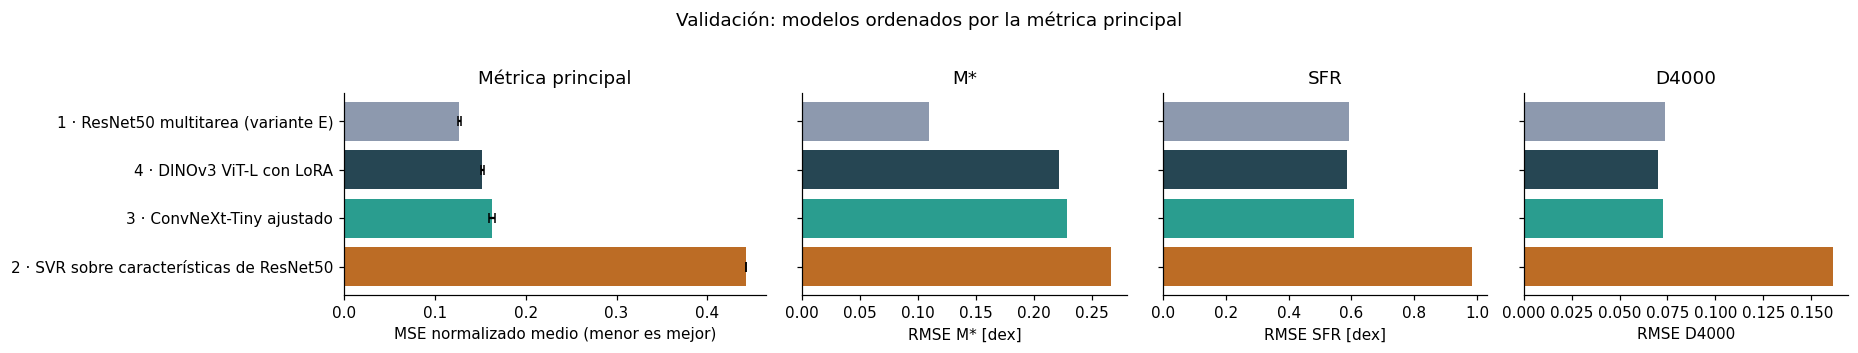

In [3]:
numeros = [int(s.split(" · ")[0]) for s in COMPARATIVA.modelo]
colores = [COLOR_MODELO.get(n, "0.5") for n in numeros]
fig, ejes = plt.subplots(1, 4, figsize=(17, 0.9 + 0.55 * len(COMPARATIVA)), sharey=True,
                         gridspec_kw={"width_ratios": [1.3, 1, 1, 1]})
y = np.arange(len(COMPARATIVA))[::-1]
ejes[0].barh(y, COMPARATIVA["MSE normalizado medio"], xerr=COMPARATIVA["desviación entre semillas"].fillna(0),
             color=colores, capsize=3)
ejes[0].set(yticks=y, yticklabels=COMPARATIVA.modelo, xlabel="MSE normalizado medio (menor es mejor)",
            title="Métrica principal")
for eje, propiedad, unidad in zip(ejes[1:], PROPIEDADES, (" [dex]", " [dex]", "")):
    eje.barh(y, COMPARATIVA[f"RMSE {propiedad}"], color=colores)
    eje.set(xlabel=f"RMSE {propiedad}{unidad}", title=propiedad)
plt.suptitle("Validación: modelos ordenados por la métrica principal", y=1.02)
plt.tight_layout(); plt.show()

Con las mismas reglas, el orden es claro. La ResNet50 multitarea en su variante E (modelo 1) obtiene el menor MSE normalizado medio (0.127), seguida de DINOv3 ViT-L con LoRA (modelo 4, 0.152) y de ConvNeXt-Tiny ajustado (modelo 3, 0.163). El SVR (modelo 2) queda muy por detrás (0.442): sus características son las de ResNet50 preentrenada con ImageNet, sin ajustar a las galaxias, y un modelo de kernel sobre ellas no alcanza a las redes ajustadas, sobre todo en la SFR (R² de 0.29) y en D4000 (R² de 0.53).

La gráfica por propiedad muestra que el orden no es el mismo en las tres. La ventaja del modelo 1 está casi toda en la masa: su RMSE de 0.109 dex es la mitad del de los demás. En la SFR y en D4000, en cambio, el mejor es DINOv3 (0.587 dex y 0.070); en la SFR le sigue el modelo 1 (0.592 dex) y en D4000 los modelos 3 y 1 quedan casi empatados (0.073 y 0.074). La diferencia en la masa tiene una explicación física que pesa en la elección final (sección 6): el modelo 1 recibe además el redshift medido con el espectro, que fija la distancia de la galaxia, y la masa depende de la luminosidad, que no se puede calcular sin la distancia.

Los tiempos de entrenamiento van de segundos en el SVR a 24 minutos por semilla en DINOv3. El tiempo del modelo 1 no quedó registrado en su cuaderno, porque recuperamos sus entrenamientos de corridas anteriores, y del SVR solo registramos el tiempo de su ajuste, sin la extracción de características.

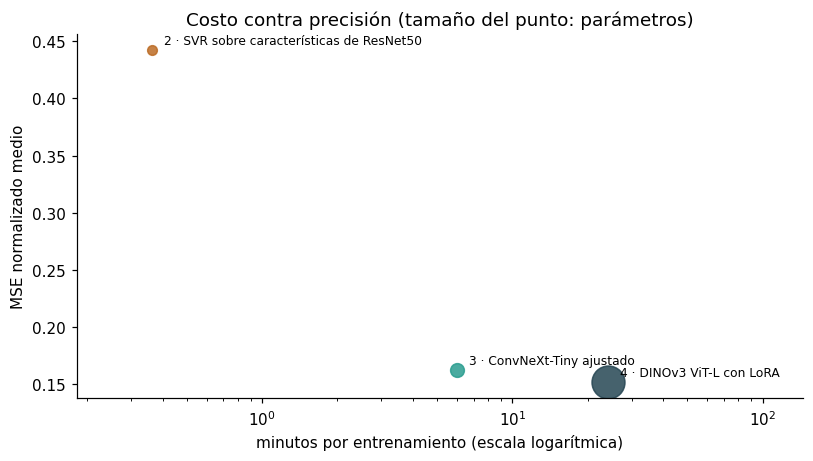

In [4]:
fig, eje = plt.subplots(figsize=(7.5, 4.3))
con_tiempo = COMPARATIVA.dropna(subset=["min por entrenamiento"])
for _, r in con_tiempo.iterrows():
    n = int(r.modelo.split(" · ")[0])
    tam = 40 if np.isnan(r["parámetros (M)"]) else 30 + 2.5 * r["parámetros (M)"] ** 0.9
    eje.scatter(r["min por entrenamiento"], r["MSE normalizado medio"], s=tam, color=COLOR_MODELO.get(n, "0.5"), alpha=0.85)
    eje.annotate(r.modelo, (r["min por entrenamiento"], r["MSE normalizado medio"]), textcoords="offset points",
                 xytext=(8, 4), fontsize=8)
eje.set_xlim(con_tiempo["min por entrenamiento"].min() / 2, con_tiempo["min por entrenamiento"].max() * 6)
eje.set(xscale="log", xlabel="minutos por entrenamiento (escala logarítmica)", ylabel="MSE normalizado medio",
        title="Costo contra precisión (tamaño del punto: parámetros)")
plt.tight_layout(); plt.show()

La gráfica de costo contra precisión resume el compromiso entre los modelos con tiempo registrado. DINOv3 es el más preciso de ellos, pero cuesta cuatro veces más entrenarlo que ConvNeXt (24 contra 6 minutos por semilla en una A100), tiene once veces más parámetros en total (308 M contra 28 M, aunque con LoRA solo se entrenan 5.1 M) y tarda seis veces más en predecir (2.7 contra 0.45 ms por galaxia). El SVR es el más barato con diferencia, pero su error es casi el triple.

## 4. Selección de los dos mejores modelos

Por la métrica principal en validación, los dos mejores modelos son la **ResNet50 multitarea (modelo 1)** y **DINOv3 ViT-L con LoRA (modelo 4)**. ConvNeXt-Tiny (modelo 3) queda en tercer lugar, a 0.010 de DINOv3; como también lo ajustamos a fondo, lo conservamos en el análisis del ajuste fino como referencia de una red más ligera.

In [5]:
DOS_MEJORES = COMPARATIVA.head(2)[["modelo", "MSE normalizado medio", "desviación entre semillas", "RMSE M*", "RMSE SFR", "RMSE D4000"]]
display(DOS_MEJORES.round(4))

,modelo,MSE normalizado medio,desviación entre semillas,RMSE M*,RMSE SFR,RMSE D4000
lugar,,,,,,
1,1 · ResNet50 multitarea (variante E),0.1269,0.0015,0.1093,0.5922,0.0736
2,4 · DINOv3 ViT-L con LoRA,0.1522,0.0017,0.2213,0.5871,0.0702


## 5. Ajuste fino de los mejores modelos

Seleccionar los mejores modelos solo tiene sentido si cada uno llegó a la comparación en su mejor configuración. Ajustamos cada modelo en su cuaderno con una estrategia adecuada a su costo. La tabla resume, para cada uno, el punto de partida, el espacio explorado, el número de experimentos y el resultado, siempre con el criterio de validación.

| Modelo | Punto de partida | Qué ajustamos | Experimentos | Método |
|---|---|---|---|---|
| 1 · ResNet50 | Variante A: una red por propiedad, imagen RGB, pérdida MSE | Arquitectura (redes separadas o una red multitarea), representación de la imagen (RGB o bandas GRZ), entradas (con o sin redshift) y pérdida (MSE o Huber) | 7 variantes × 3 semillas = 21 corridas (27 redes) | Diseño de experimentos con contrastes pareados entre variantes |
| 4 · DINOv3 | ViT congelado con una cabeza | Tamaño del modelo (ViT-S, B, L y L satelital), presentación de la imagen, resumen de los tokens, resolución, variante de entrada; hiperparámetros de la cabeza; estrategia de ajuste fino (últimos bloques o LoRA), rango de LoRA, bloques abiertos, tasas de aprendizaje, *weight decay*, decaimiento por capa, *stochastic depth* | 48 combinaciones congeladas, 2 resoluciones, 40 pruebas de la cabeza y 16 de ajuste fino; finalista con 3 semillas | Barrido completo de las representaciones congeladas y Optuna (TPE con poda por *successive halving*) |
| 3 · ConvNeXt-Tiny | Pesos de ImageNet-22k, tasa 10⁻⁴, Huber | Pesos preentrenados (ImageNet-1k, ImageNet-22k o destilados de DINOv3), variante de entrada, tasa del extractor y de la cabeza, *weight decay*, decaimiento por capa, *drop path*, pérdida y calentamiento | 6 corridas base, 30 pruebas de Optuna, 3 finalistas con todas las épocas y el ganador con 3 semillas | Optuna (TPE con poda por *successive halving*) |

,modelo,antes,criterio_antes,sd_antes,despues,criterio_despues,sd_despues,reducción del criterio
0,1 · ResNet50,variante A (inicial),0.1838,0.0019,variante E,0.1269,0.0015,31 %
1,4 · DINOv3,ViT-L congelado con la mejor cabeza,0.2590,0.0024,ViT-L con LoRA de rango 32,0.1522,0.0017,41 %
2,3 · ConvNeXt-Tiny,configuración de partida,0.1769,0.0019,configuración de Optuna,0.1625,0.0031,8 %


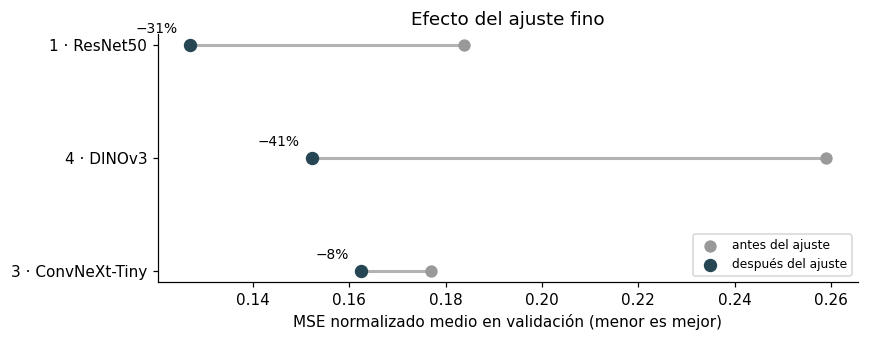

In [6]:
AJUSTE = pd.DataFrame([
    dict(modelo="1 · ResNet50", antes="variante A (inicial)", criterio_antes=0.183782, sd_antes=0.001921,
         despues="variante E", criterio_despues=0.126881, sd_despues=0.001525),
    dict(modelo="4 · DINOv3", antes="ViT-L congelado con la mejor cabeza", criterio_antes=0.2590, sd_antes=0.0024,
         despues="ViT-L con LoRA de rango 32", criterio_despues=0.1522, sd_despues=0.0017),
    dict(modelo="3 · ConvNeXt-Tiny", antes="configuración de partida", criterio_antes=0.1769, sd_antes=0.0019,
         despues="configuración de Optuna", criterio_despues=0.1625, sd_despues=0.0031),
])
AJUSTE["reducción del criterio"] = 1 - AJUSTE.criterio_despues / AJUSTE.criterio_antes
TABLA_AJUSTE = AJUSTE.round(4)
TABLA_AJUSTE["reducción del criterio"] = (AJUSTE["reducción del criterio"] * 100).round(0).astype(int).astype(str) + " %"
display(TABLA_AJUSTE)

fig, eje = plt.subplots(figsize=(8, 3.2))
for k, r in AJUSTE.iterrows():
    eje.plot([r.criterio_antes, r.criterio_despues], [k, k], color="0.7", lw=2, zorder=1)
    eje.scatter(r.criterio_antes, k, color="0.6", s=50, zorder=2, label="antes del ajuste" if k == 0 else None)
    eje.scatter(r.criterio_despues, k, color="#264653", s=60, zorder=3, label="después del ajuste" if k == 0 else None)
    eje.annotate(f"−{r['reducción del criterio']:.0%}", (r.criterio_despues, k), textcoords="offset points", xytext=(-8, 8),
                 ha="right", fontsize=9)
eje.set(yticks=range(len(AJUSTE)), yticklabels=AJUSTE.modelo, xlabel="MSE normalizado medio en validación (menor es mejor)",
        title="Efecto del ajuste fino")
eje.invert_yaxis(); eje.legend(fontsize=8, loc="lower right"); plt.tight_layout(); plt.show()

El ajuste fino mejoró a los tres modelos, con distinta profundidad. En la **ResNet50**, el ajuste fue de diseño. Las siete variantes A a G cambian una decisión a la vez, y los contrastes entre ellas, con tres semillas, muestran qué aporta cada una: compartir el extractor entre las tres propiedades (de A a B) casi no cambia el error, usar las bandas GRZ en lugar de RGB mejora un poco, y agregar el redshift reduce el criterio de 0.178 a 0.129 (de F a D), sobre todo por la masa. La pérdida de Huber da la última mejora pequeña (de D a E). En total, el criterio baja 31 %, de 0.184 a 0.127. Esta exploración no incluyó una búsqueda de la tasa de aprendizaje ni del *weight decay*, que quedaron fijos, así que es posible que la variante E todavía pueda mejorar con una búsqueda como la de los modelos 3 y 4.

En **DINOv3**, el ajuste se hizo en dos niveles. Primero, un barrido completo de las representaciones congeladas mostró que la imagen en color de Lupton, un modelo de al menos el tamaño de ViT-B y el token CLS son la mejor base, y 40 pruebas de Optuna ajustaron la cabeza. Después, la búsqueda de ajuste fino encontró que LoRA de rango 32 con una tasa de unos 2 × 10⁻⁴ supera a abrir los últimos bloques. El criterio baja 41 %, de 0.259 a 0.152. Esta búsqueda fue la más corta en número de pruebas completas (3 de 16, por la poda y el costo de ViT-L), así que su resultado debe tomarse como una buena configuración y no necesariamente como la óptima.

En **ConvNeXt-Tiny**, 30 pruebas de Optuna sobre nueve hiperparámetros redujeron el criterio 8 %, de 0.177 a 0.163. El hiperparámetro más importante fue el decaimiento de la tasa por capa (importancia fANOVA de 0.58): las mejores configuraciones dejan que todas las capas se adapten casi por igual, lo que indica que las imágenes de galaxias son lo bastante distintas de ImageNet como para que también las primeras capas tengan que cambiar.

## 6. Elección del modelo individual final

El ajuste fino deja a los dos mejores modelos, la ResNet50 multitarea (variante E) y DINOv3 ViT-L con LoRA, en su mejor versión. Para elegir entre ellos, la tabla los compara en todos los aspectos que importan para el uso del modelo, no solo en la métrica principal; ConvNeXt-Tiny aparece como referencia de una opción más ligera.

| Aspecto | 1 · ResNet50 (variante E) | 4 · DINOv3 ViT-L + LoRA | 3 · ConvNeXt-Tiny |
|---|---|---|---|
| MSE normalizado medio en validación | **0.127** | 0.152 | 0.163 |
| RMSE de la masa (dex) | **0.109** | 0.221 | 0.228 |
| RMSE de la SFR (dex) | 0.592 | **0.587** | 0.607 |
| RMSE de D4000 | 0.074 | **0.070** | 0.073 |
| Datos que necesita al predecir | imagen **y redshift espectroscópico** | **solo la imagen** | **solo la imagen** |
| Estabilidad entre semillas (desviación del criterio) | 0.0015 | 0.0017 | 0.0031 |
| Sobreajuste (error de validación / entrenamiento) | no reportado | **1.01 a 1.17** | 1.26 a 1.41 |
| Parámetros totales / entrenables | 25 M / 25 M | 308 M / 5.1 M | 28 M / 28 M |
| Tiempo por entrenamiento | no reportado (RTX A4000) | 24 min (A100) | **6 min** (A100) |
| Tiempo de inferencia por galaxia | no reportado | 2.7 ms | **0.45 ms** |
| Interpretabilidad (oclusión) | no evaluada | usa la galaxia, sobre todo el centro; nada más allá de 4 R50 | usa la galaxia; la SFR depende del disco hasta 2 R50 |
| Licencia de los pesos preentrenados | torchvision (BSD-3) | licencia propia de DINOv3 | Apache 2.0 |

**Elegimos DINOv3 ViT-L con LoRA (modelo 4) como modelo individual final.** La razón principal no es la métrica, sino el requisito de uso. Los asesores del proyecto establecieron que, al aplicar el modelo a galaxias nuevas, solo estará disponible su imagen. El redshift espectroscópico requiere un espectro de cada galaxia, que es justamente la medición costosa que el proyecto busca evitar; para la gran mayoría de las galaxias de DESI no existe. La variante E necesita ese dato como entrada, así que no se puede aplicar en el escenario para el que construimos el modelo, y su ventaja en la métrica principal viene casi toda de la masa, que es la propiedad que más depende de la distancia.

Entre los modelos que solo necesitan la imagen, DINOv3 es el mejor en validación y en prueba, y es el mejor de todos en la SFR y en D4000, incluso frente a la variante E con el redshift medido. Además, es el más estable entre semillas y el que menos se sobreajusta, y su análisis de oclusión muestra que basa sus predicciones en la galaxia y no en el fondo ni en las fuentes vecinas.

Su desventaja es el costo: cuatro veces más tiempo de entrenamiento y seis veces más tiempo de inferencia que ConvNeXt-Tiny, y una licencia más restrictiva. Para este proyecto el costo es aceptable: 2.7 ms por galaxia equivalen a unos 45 minutos de GPU por cada millón de galaxias, y basta entrenarlo una sola vez. Si en una etapa posterior hubiera que procesar catálogos de cientos de millones de galaxias o con recursos limitados, ConvNeXt-Tiny es la alternativa recomendada: su criterio es entre 6 y 7 % mayor en validación y en prueba, pero es seis veces más rápido y su licencia es abierta.

## 7. Desempeño del modelo final en el conjunto de prueba

Con el modelo final elegido, queda medir su desempeño en galaxias que no intervinieron en ninguna decisión. Abrimos el conjunto de prueba una sola vez, después de registrar la elección en el cuaderno del modelo 4 (sección 12). La tabla compara el modelo final con las dos referencias de Katachi sobre las mismas 917 galaxias: **Katachi publicado**, con sus pesos originales entrenados con imágenes de SDSS, y el **baseline del Avance 3**, la misma cadena reentrenada por el equipo con imágenes de DESI.

In [7]:
PRUEBA = pd.DataFrame({
    "Katachi publicado (SDSS)": [0.222, 0.668, 0.100],
    "Baseline del Avance 3 (DESI)": [0.222, 0.653, 0.073],
    "Modelo final: DINOv3 ViT-L + LoRA": [0.2222, 0.6078, 0.0716],
}, index=pd.Index(["log M* [dex]", "log SFR [dex]", "D4000"], name="RMSE en prueba"))
PRUEBA["cambio frente a Katachi"] = PRUEBA.iloc[:, 2] / PRUEBA.iloc[:, 0] - 1
PRUEBA["cambio frente al baseline"] = PRUEBA.iloc[:, 2] / PRUEBA.iloc[:, 1] - 1
PRUEBA["veredicto pareado frente al baseline (3 semillas)"] = ["equivalente o no concluyente", "mejor en las 3", "equivalente en las 3"]
TABLA_PRUEBA = PRUEBA.round(3)
for columna in ("cambio frente a Katachi", "cambio frente al baseline"):
    TABLA_PRUEBA[columna] = (PRUEBA[columna] * 100).round(0).astype(int).map("{:+d} %".format)
display(TABLA_PRUEBA)
print("MSE normalizado medio en prueba: 0.1597 ± 0.0002 (3 semillas) · en validación: 0.1522 ± 0.0017")

,Katachi publicado (SDSS),Baseline del Avance 3 (DESI),Modelo final: DINOv3 ViT-L + LoRA,cambio frente a Katachi,cambio frente al baseline,veredicto pareado frente al baseline (3 semillas)
RMSE en prueba,,,,,,
log M* [dex],0.222,0.222,0.222,+0 %,+0 %,equivalente o no concluyente
log SFR [dex],0.668,0.653,0.608,-9 %,-7 %,mejor en las 3
D4000,0.100,0.073,0.072,-28 %,-2 %,equivalente en las 3


MSE normalizado medio en prueba: 0.1597 ± 0.0002 (3 semillas) · en validación: 0.1522 ± 0.0017


En la prueba, el modelo final obtiene un MSE normalizado medio de 0.160, cerca del 0.152 de validación, así que la selección no infló el resultado más de lo esperable. Frente a Katachi publicado reduce el error de la SFR en 9 % y el de D4000 en 28 %, y lo iguala en la masa. Frente al baseline del Avance 3 mejora la SFR en 7 %, con intervalos de confianza que excluyen el cero en las tres semillas, y lo iguala en la masa y en D4000. El detalle de estas comparaciones, con sus intervalos, está en la sección 12 del cuaderno del modelo 4.

## 8. Conclusiones

La comparación con reglas comunes deja un orden claro en validación. La ResNet50 multitarea en su variante E obtiene el menor MSE normalizado medio (0.127), seguida de DINOv3 ViT-L con LoRA (0.152), de ConvNeXt-Tiny (0.163) y del SVR (0.442). El orden, sin embargo, cambia según la propiedad. La ventaja de la ResNet50 está casi toda en la masa y proviene del redshift espectroscópico que recibe como entrada, mientras que en la SFR y en D4000 el mejor modelo es DINOv3.

El ajuste fino mejoró a los tres modelos ajustados. La exploración de diseño redujo el criterio de la ResNet50 en 31 %, el paso de DINOv3 congelado a LoRA lo redujo en 41 % y la búsqueda con Optuna, en 8 % para ConvNeXt-Tiny. Las búsquedas dejaron además aprendizajes que van más allá de cada modelo: con estas imágenes conviene que todas las capas de la red se adapten, y un modelo fundacional general no basta congelado, pero es el mejor punto de partida cuando se ajusta.

Elegimos DINOv3 ViT-L con LoRA como modelo final porque es el mejor de los modelos que se pueden aplicar solo con la imagen, que es el requisito de uso del proyecto, y porque además es el más estable entre semillas y el que menos se sobreajusta. En la prueba confirma lo observado en validación: mejora a Katachi publicado en la SFR y en D4000, y al baseline del Avance 3 en la SFR, con la misma precisión en la masa. Su costo de cómputo es mayor, y ConvNeXt-Tiny queda como alternativa cuando la rapidez sea la prioridad.

Para la siguiente etapa quedan pendientes incorporar los modelos 5 y 6 a la comparación, registrar el tiempo de entrenamiento de la ResNet50, ampliar la búsqueda de LoRA, que tuvo pocas pruebas completas, y probar más épocas de entrenamiento, ya que el criterio de DINOv3 seguía mejorando al terminar.

## 9. Referencias

Akiba, T., Sano, S., Yanase, T., Ohta, T. y Koyama, M. (2019). Optuna: A next-generation hyperparameter optimization framework. *Proceedings of the 25th ACM SIGKDD*, 2623–2631.

Drucker, H., Burges, C. J. C., Kaufman, L., Smola, A. y Vapnik, V. (1997). Support vector regression machines. *Advances in Neural Information Processing Systems*, 9, 155–161.

Géron, A. (2022). *Hands-On Machine Learning with Scikit-Learn, Keras, and TensorFlow* (3.ª ed.). O'Reilly Media. Capítulo 2, sección *Fine-Tune Your Model*.

He, K., Zhang, X., Ren, S. y Sun, J. (2016). Deep residual learning for image recognition. *CVPR*, 770–778.

Hu, E. J., Shen, Y., Wallis, P., et al. (2022). LoRA: Low-rank adaptation of large language models. *ICLR*.

Liu, Z., Mao, H., Wu, C.-Y., Feichtenhofer, C., Darrell, T. y Xie, S. (2022). A ConvNet for the 2020s. *CVPR*, 11976–11986.

Siméoni, O., Vo, H. V., Seitzer, M., et al. (2025). DINOv3. arXiv:2508.10104.

Studer, S., Bui, T. B., Drescher, C., et al. (2021). Towards CRISP-ML(Q): A machine learning process model with quality assurance methodology. *Machine Learning and Knowledge Extraction*, 3, 392–413.

## 10. Declaración sobre el uso de herramientas de inteligencia artificial

Somos responsables del planteamiento del problema, de la obtención y preparación de los datos, del protocolo de comparación, de la selección de los modelos y de las decisiones metodológicas de este avance, como predecir solo a partir de la imagen y reservar el conjunto de prueba para el modelo final. También ejecutamos todos los entrenamientos, analizamos los resultados y validamos cada conclusión.

Utilizamos **Claude** (Anthropic) como asistente durante el desarrollo, para apoyar la implementación de parte del código y sus pruebas, y la redacción de los análisis a partir de los resultados obtenidos. Revisamos todo lo que produjo la herramienta, lo corregimos cuando hizo falta y lo validamos, y asumimos la responsabilidad del contenido. Los resultados numéricos provienen de las ejecuciones de los cuadernos.